# **BAB II: IMPLEMENTASI KASUS PROBABILITAS (SKENARIO TI)**

## **Kasus 1: Teorema Bayes – Filtering Phishing pada Log Traffic Email**

In [1]:
print("=== Kasus 1: Teorema Bayes (Filtering Phishing) ===")

p_phishing = 0.04
p_ham = 0.96
p_urgent_given_phishing = 0.90
p_urgent_given_ham = 0.05

p_urgent_total = (p_urgent_given_phishing * p_phishing) + (p_urgent_given_ham * p_ham)
p_phishing_given_urgent = (p_urgent_given_phishing * p_phishing) / p_urgent_total

print(f"Probabilitas Phishing jika terdapat kata 'Urgent':")
print(f"{p_phishing_given_urgent:.4f} atau ({p_phishing_given_urgent*100:.2f}%)")

=== Kasus 1: Teorema Bayes (Filtering Phishing) ===
Probabilitas Phishing jika terdapat kata 'Urgent':
0.4286 atau (42.86%)


## **Kasus 2: Simulasi Monte Carlo – Ketersediaan (Availability) Cluster Server Redundan**


In [2]:
import numpy as np

print("=== Kasus 2: Simulasi Monte Carlo (Server Redundan) ===")

np.random.seed(42)
N_simulations = 1_000_000

servers = np.random.binomial(n=1, p=0.15, size=(N_simulations, 3))
system_failures = np.all(servers == 1, axis=1)
prob_simulasi = np.mean(system_failures)

print(f"Hasil Simulasi ({N_simulations:,} iterasi): {prob_simulasi:.6f}")
print(f"Estimasi Ketersediaan Sistem: {(1 - prob_simulasi)*100:.4f}%")

=== Kasus 2: Simulasi Monte Carlo (Server Redundan) ===
Hasil Simulasi (1,000,000 iterasi): 0.003370
Estimasi Ketersediaan Sistem: 99.6630%


# **BAB III: IMPLEMENTASI DISTRIBUSI PROBABILITAS (DISKRIT & KONTINU)**

# **Kasus 1: Distribusi Poisson (Diskrit) – Analisis DDoS & Rate Limiting API**

=== Kasus 1: Distribusi Poisson (DDoS API) ===
Probabilitas Rate Limiting terpicu (X > 18): 0.0374 (3.74%)



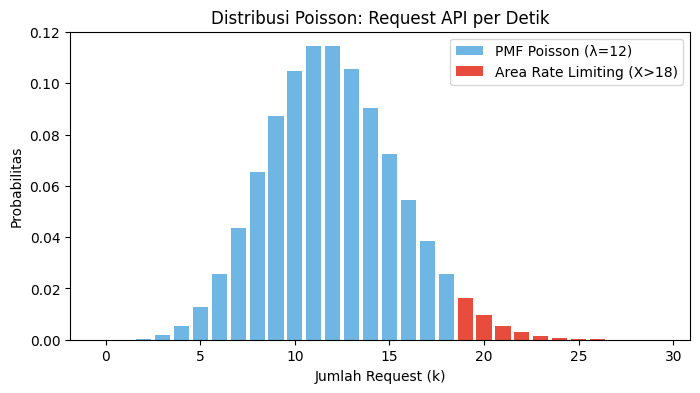

In [3]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import numpy as np

print("=== Kasus 1: Distribusi Poisson (DDoS API) ===")

lambda_val = 12
threshold = 18

prob_rate_limit = stats.poisson.sf(threshold, lambda_val)
print(f"Probabilitas Rate Limiting terpicu (X > 18): {prob_rate_limit:.4f} ({prob_rate_limit*100:.2f}%)\n")

x_poisson = np.arange(0, 30)
pmf_poisson = stats.poisson.pmf(x_poisson, lambda_val)

plt.figure(figsize=(8, 4))
plt.bar(x_poisson, pmf_poisson, color='#3498DB', alpha=0.7, label='PMF Poisson (λ=12)')
plt.bar(x_poisson[threshold+1:], pmf_poisson[threshold+1:], color='#E74C3C', label='Area Rate Limiting (X>18)')
plt.title('Distribusi Poisson: Request API per Detik')
plt.xlabel('Jumlah Request (k)')
plt.ylabel('Probabilitas')
plt.legend()
plt.show()

# **Kasus 2: Distribusi Weibull (Kontinu) – MTBF & Failure Rate SSD Data Center**

=== Kasus 2: Distribusi Weibull (Kerusakan SSD) ===
Probabilitas SSD Rusak < 3 Tahun: 0.3717 (37.17%)



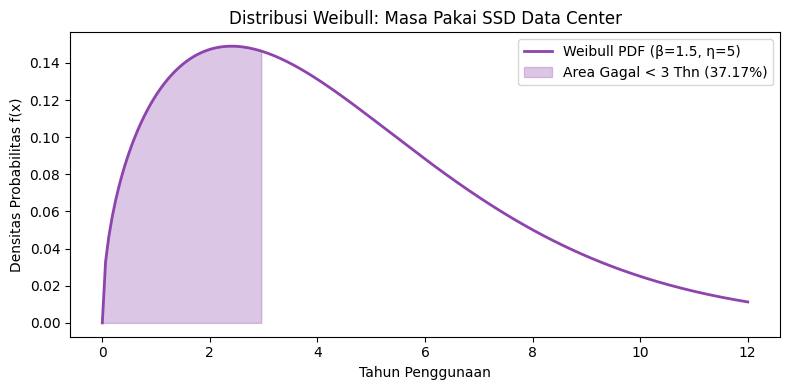

In [4]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import numpy as np

print("=== Kasus 2: Distribusi Weibull (Kerusakan SSD) ===")

beta = 1.5
eta = 5

prob_fail_3yrs = stats.weibull_min.cdf(3, c=beta, scale=eta)
print(f"Probabilitas SSD Rusak < 3 Tahun: {prob_fail_3yrs:.4f} ({prob_fail_3yrs*100:.2f}%)\n")

x_weibull = np.linspace(0, 12, 200)
pdf_weibull = stats.weibull_min.pdf(x_weibull, c=beta, scale=eta)

plt.figure(figsize=(8, 4))
plt.plot(x_weibull, pdf_weibull, color='#8E44AD', lw=2, label='Weibull PDF (β=1.5, η=5)')
plt.fill_between(x_weibull, pdf_weibull, where=(x_weibull <= 3), color='#8E44AD', alpha=0.3, label='Area Gagal < 3 Thn (37.17%)')
plt.title('Distribusi Weibull: Masa Pakai SSD Data Center')
plt.xlabel('Tahun Penggunaan')
plt.ylabel('Densitas Probabilitas f(x)')
plt.legend()
plt.tight_layout()
plt.show()